Short notebook going through the calculations done for obtaining an ideal waveguide configuration for degenerate Type-0 SPDC in thin-film Lithium Niobate. We make use of the SNOW library and consider low-gain solutions for the joint spectral amplitude(JSA) which is used to obtain the Schmidt number.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import colorcet as cc
from tqdm import tqdm

from scipy.signal import peak_widths
from scipy.signal import find_peaks


import snow.waveguides as waveguides
from scipy.constants import c

# Defining constants for plotting purposes
nm = 1e-9
um = 1e-6
mm = 1e-3
fs = 1e-15
THz = 1e12

## Finding configurations where the group-velocity matching condition is met

We first being by calculating the Group-velocity mismatch (GVM) for different configurations of etch and width. The overall thin film layer(etch+slab) is kept constant. NOte that differently from Liam's notebook, I vary the slab width rather than the etch. For a quicker run time, lower the number of points in the arrays. Higher number points gives a better interpolation when finding the GVM=0 contour.

In [2]:
p_wl = 1045 * nm  # Pump wavelength
s_wl = 2 * p_wl  # Signal wavelength

# Waveguide parameters
angle = 70
hLN = 700 * nm  # Thinfilm thickness
width = np.linspace(500 * nm, 2700 * nm, 301)  # Array of top widths
slab = np.linspace(130 * nm, 400 * nm, 301)  # Array of slab thickness


actual_etch = hLN - slab

# Calculate GVM for each geometry
GVM = np.zeros([width.size, slab.size])
for ke in tqdm(range(slab.size)):
    for kw in range(width.size):
        # Define waveguide structure
        wg = waveguides.waveguide(
            w_top=width[kw],  # Ridge width
            h_thinfilm=hLN,  # Thinfilm thickness
            h_etch=hLN - slab[ke],  # Etch depth hLN-slab[ke]
            theta=angle,  # Sidewall angle
            tf_material="LN_MgO_e",  # Thinfilm medium (_e for extraordinary axis, _o for ordinary)
            clad_material="Air",  # Cladding medium
            box_material="SiO2",  # Substrate medium
        )
        GVM[kw, ke] = wg.beta1(p_wl)[0] - wg.beta1(s_wl)[0]


# Renormalizing
GVM = GVM / (fs / mm)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 301/301 [03:28<00:00,  1.44it/s]


We plot the GVM and include the contour where it is 0.

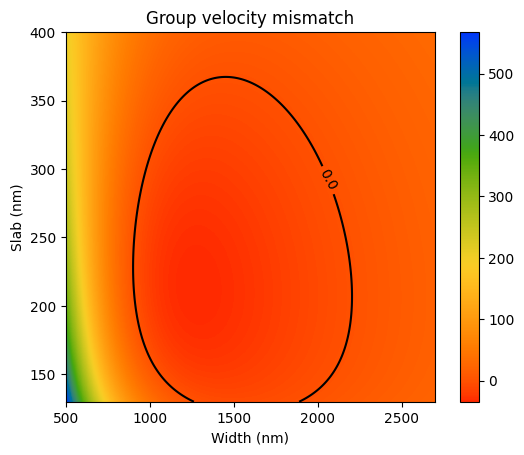

In [3]:
fig, ax = plt.subplots()
im = ax.imshow(
    GVM.T,
    cmap=cc.cm["rainbow_r"],
    origin="lower",
    extent=[width[0] / nm, width[-1] / nm, slab[0] / nm, slab[-1] / nm],
    aspect=(width[-1] - width[0]) / (slab[-1] - slab[0]),
)
ax.set_xlabel("Width (nm)")
ax.set_ylabel("Slab (nm)")
ax.set_title("Group velocity mismatch")
cs = plt.contour(width / nm, slab / nm, GVM.T, [0], colors="black")
plt.clabel(cs, fmt="%1.1f")
plt.colorbar(im, orientation="vertical")
plt.show()

## Isolating the GVM=0 configurtion and looking at the group-velocity dispersion

With the contour, we can use built in functions and isolate the points (width, slab) which are 0. Contourplot finds these points through interpolation, and hence we can play around with our configuartion space to get better/quicker results. Depending on the chosen parameter space, it might be that the contour is discontinuous, if this is the case, we need to be more careful. The commented out code in the 2nd half of the next cell works for 2 separate regions.

In [4]:
# From the contour plot, we can get the path and find the interpolated values that gave us said contour
p = cs.collections[0].get_paths()[0].vertices
# p is an array of points (width,slab) where GVM=0
# Renormalization
p = p * nm


# If there are two disjoint regions when the contour is 0
# p1 = cs.collections[0].get_paths()[0].vertices
# p2 = cs.collections[0].get_paths()[1].vertices
# p = np.concatenate((p1,p2),axis=0)
# p=p*nm

/tmp/ipykernel_16618/887180017.py:2: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  p = cs.collections[0].get_paths()[0].vertices


Now that we have isolated the points where the GVM is 0, we can calculate the group-velocity dispersion(GVD) at each of these points for both the signal and the pump.

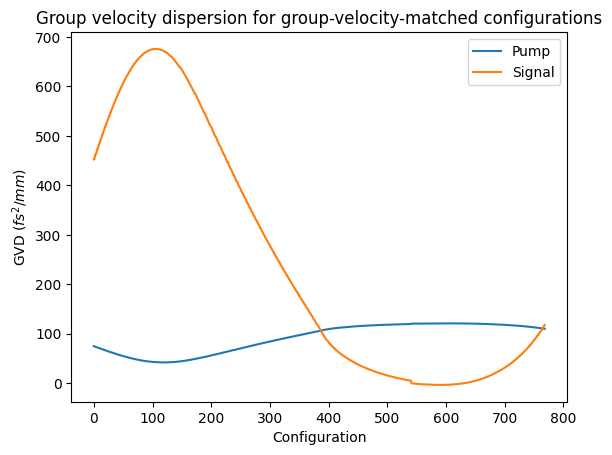

In [5]:
GVD = np.zeros_like(p)
for kw in range(len(p)):
    wg = waveguides.waveguide(
        w_top=p[kw, 0],
        h_thinfilm=hLN,
        h_etch=hLN - p[kw, 1],
        theta=angle,
        tf_material="LN_MgO_e",
        clad_material="Air",
        box_material="SiO2",
    )
    GVD[kw, 0] = wg.GVD(p_wl)[0]
    GVD[kw, 1] = wg.GVD(s_wl)[0]

# Renormalization
GVD = GVD / (fs**2 / mm)

fig, ax1 = plt.subplots()
ax1.plot(GVD[:, 0], label="Pump")
ax1.plot(GVD[:, 1], label="Signal")
ax1.set_xlabel(r"Configuration")
ax1.set_ylabel(r"GVD $(fs^2/mm)$")
ax1.set_title(r"Group velocity dispersion for group-velocity-matched configurations")
ax1.legend()
plt.show()

Testing to see that the solutions we obtained from the contour plot actually gives GVM=0

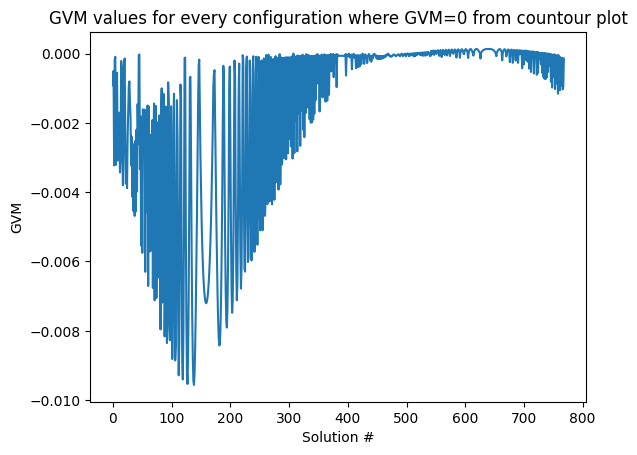

In [6]:
GVM_tst = np.zeros_like(p)
for kw in range(len(p)):
    wg = waveguides.waveguide(
        w_top=p[kw, 0],
        h_thinfilm=hLN,
        h_etch=hLN - p[kw, 1],
        theta=angle,
        tf_material="LN_MgO_e",
        clad_material="Air",
        box_material="SiO2",
    )
    GVM_tst[kw, 0] = wg.beta1(p_wl)[0] - wg.beta1(s_wl)[0]

# Renorm
GVM_tst = GVM_tst / (fs / mm)

fig, ax1 = plt.subplots()
ax1.plot(GVM_tst[:, 0])
ax1.set_xlabel(r"Solution #")
ax1.set_ylabel(r"GVM")
ax1.set_title(r"GVM values for every configuration where GVM=0 from countour plot")
plt.show()

As we can see, GVM isn't ever really 0 (everything is obtained through interpolation), but in the end we need it to be relatively small compared to the GVD terms in the phase-matching condition.

Theoretically, we want GVDs>>GVDp and so there are two different ways we could obtain this. By first maximizing GVDs or minimizing GVDp.

In [7]:
# Index which maximizes GVDs
gvd_ax = np.unravel_index(GVD[:, 1].argmax(), GVD[:, 1].shape)
index_gvdsmax = gvd_ax[0]
gvd_ax[0]

np.int64(105)

In [8]:
# Index that minimizes GVDp
gvd_ax = np.unravel_index(GVD[:, 0].argmin(), GVD[:, 0].shape)
index_gvdpmin = gvd_ax[0]
gvd_ax[0]

np.int64(120)

## Low-gain analysis of semi-optimal configuration

Now we can generate a waveguide that has the parameters associated with the properties we want. We also calculate the poling period for 0th order phase-matching. Note that we focus on the case where GVDs is maximized.

In [9]:
wg_test = waveguides.waveguide(
    w_top=p[index_gvdsmax, 0],
    h_thinfilm=hLN,
    h_etch=hLN - p[index_gvdsmax, 1],
    theta=angle,
    tf_material="LN_MgO_e",
    clad_material="Air",
    box_material="SiO2",
)


n1 = wg_test.neff(p_wl)[0]
n2 = wg_test.neff(s_wl)[0]
pp = p_wl / (n1 - n2)
print("poling required is %0.4f um" % (pp / um))

poling required is 3.9854 um


Now that we have the refractive indices and poling period for our configuration, we can imagine evaluating the low-gain limit of the JSA (product of pump amplitude and phase-matching function(PMF)) for a range of wavelengths. We consider two typical PMFS: a Sinc and a Gaussian.

In [10]:
L = 10 * mm  # Length of waveguide
wl_range = np.linspace(-0.300, 0.300, 151) * um  # wavelength range
wl = s_wl + wl_range

# Finding dispersion for pump and signal as a function of wavelength range
# Since SNOW requires 1D data, we reshape the 2D array needed for the pump term
wlp = 1 / ((1 / wl + 1 / wl[:, np.newaxis])).flatten()  # Values of pump wavelengths
kp1 = 2 * np.pi * wg_test.neff(wlp) / (wlp)  # Values of pump momenta
kp = kp1.reshape(len(wl), len(wl))  # Reshape to obtain 2D array of pump momenta
ks = 2 * np.pi * wg_test.neff(wl) / (wl)  # Signal momenta
# Different PMFs with Type-0 Phase-matching functions
PMF = np.sinc(-L * (kp - ks - ks[:, np.newaxis] - 2 * np.pi / pp) / (2 * np.pi))
PMF_g = np.exp(-((L * (kp - ks - ks[:, np.newaxis] - 2 * np.pi / pp) / 2) ** 2))

For the low gain JSA we typically work with the pump envelope in frequency space. Since SNOW works better in terms of wavelength,
we express frequency space pump envelope in terms of wavelength. We also express the standard deviation in frequency space in terms of the pulse-width of the Intensity in the time domain.

In [11]:
# Obtaining parameters for pump amplitude from intensity parameters.
Ft = 50 * fs  # pulse-width: FWHM of intensity profile
Fl = (
    2 * np.log(2) * p_wl**2 / (np.pi * c * Ft)
)  # FWHM of intensity in terms of wavelength

sig_w = 2 * np.sqrt(np.log(2)) / Ft  # Standard deviation of pump amplitude

pump = np.exp(
    -((1 / wl + 1 / wl[:, np.newaxis] - 2 / s_wl) ** 2)
    / (2 * (sig_w / (2 * np.pi * c)) ** 2)
)

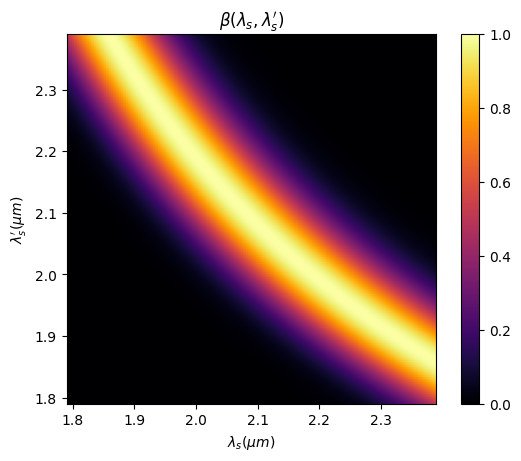

In [12]:
# Generating plot of Pump
fig, ax = plt.subplots()
im = ax.imshow(
    pump,
    cmap="inferno",
    origin="lower",
    extent=[wl[0] / um, wl[-1] / um, wl[0] / um, wl[-1] / um],
)
ax.set_xlabel(r"$\lambda_s (\mu m)$")
ax.set_ylabel(r"$\lambda_s'(\mu m)$")
ax.set_title(r"$\beta(\lambda_s,\lambda_s')$")
plt.colorbar(im, orientation="vertical")
plt.show()

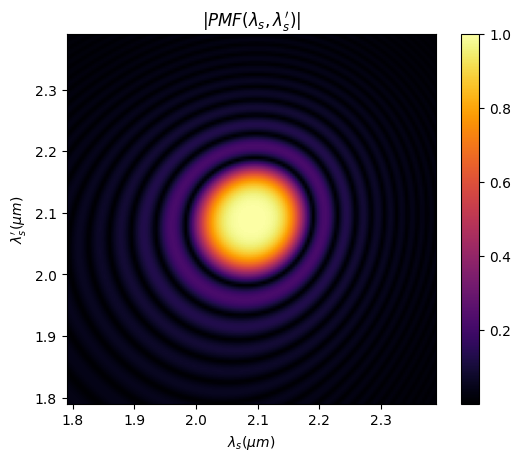

In [13]:
# Generating plot of Sinc PMF
fig, ax = plt.subplots()
im = ax.imshow(
    np.abs(PMF),
    cmap="inferno",
    origin="lower",
    extent=[wl[0] / um, wl[-1] / um, wl[0] / um, wl[-1] / um],
)
ax.set_xlabel(r"$\lambda_s (\mu m)$")
ax.set_ylabel(r"$\lambda_s'(\mu m)$")
ax.set_title(r"$|PMF(\lambda_s,\lambda_s')|$")
plt.colorbar(im, orientation="vertical")
plt.show()

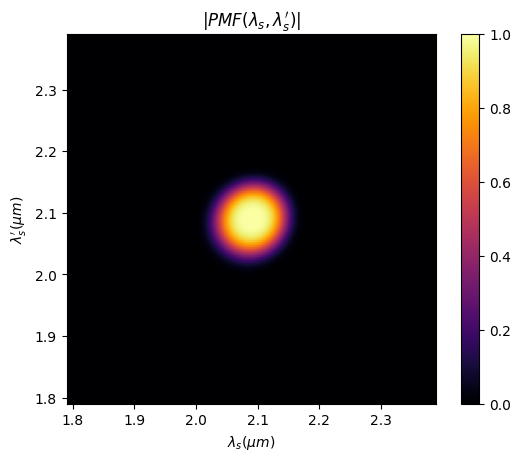

In [14]:
# Generating plot for Gaussian PMF
fig, ax = plt.subplots()
im = ax.imshow(
    np.abs(PMF_g),
    cmap="inferno",
    origin="lower",
    extent=[wl[0] / um, wl[-1] / um, wl[0] / um, wl[-1] / um],
)
ax.set_xlabel(r"$\lambda_s (\mu m)$")
ax.set_ylabel(r"$\lambda_s'(\mu m)$")
ax.set_title(r"$|PMF(\lambda_s,\lambda_s')|$")
plt.colorbar(im, orientation="vertical")
plt.show()

We now considering the actual JSA for Sinc PMF

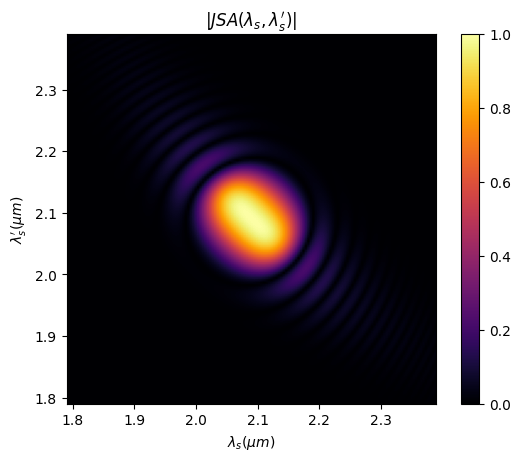

In [15]:
# Generating plot of low-gain JSA
fig, ax = plt.subplots()
im = ax.imshow(
    np.abs(PMF * pump),
    cmap="inferno",
    origin="lower",
    extent=[wl[0] / um, wl[-1] / um, wl[0] / um, wl[-1] / um],
)
ax.set_xlabel(r"$\lambda_s (\mu m)$")
ax.set_ylabel(r"$\lambda_s'(\mu m)$")
ax.set_title(r"$|JSA(\lambda_s,\lambda_s')|$")
plt.colorbar(im, orientation="vertical")
plt.show()

Next we imagine the case where we can apodize the sample to generate a perfectly Gaussian PMF. This scenario is even better as it kills off all the "side-lobes"

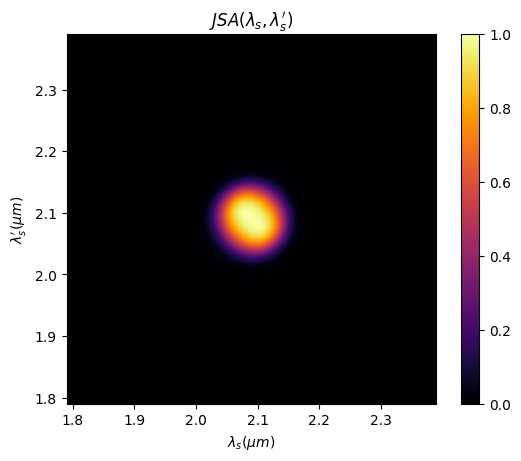

In [16]:
# Generating plot of Pump
fig, ax = plt.subplots()
im = ax.imshow(
    PMF_g * pump,
    cmap="inferno",
    origin="lower",
    extent=[wl[0] / um, wl[-1] / um, wl[0] / um, wl[-1] / um],
)
ax.set_xlabel(r"$\lambda_s (\mu m)$")
ax.set_ylabel(r"$\lambda_s'(\mu m)$")
ax.set_title(r"$JSA(\lambda_s,\lambda_s')$")
plt.colorbar(im, orientation="vertical")
plt.show()

Next we obtain a numerical Schmidt decomposition and evaluate the Schmidt number. Note that the numbers obtained in both cases are very close to the values obtained in Type-2 SPDC (see my Good, Bad, Ugly paper). Increasing the length of the waveguide will give better results: Causes the central blobs to me narrower along the diagonal.

In [17]:
L2, D, Vh = np.linalg.svd(
    0.000000001
    * PMF
    * pump
    * np.exp(1j * (-ks - ks[:, np.newaxis] - 2 * np.pi / pp) * L / 2)
)
D = np.diag(D)
K_gvdpmin = (np.trace(np.sinh(D) ** 2)) ** 2 / np.trace(np.sinh(D) ** 4)

L2g, Dg, Vhg = np.linalg.svd(0.000000001 * PMF_g * pump)
Dg = np.diag(Dg)
Kg_gvdpmin = (np.trace(np.sinh(Dg) ** 2)) ** 2 / np.trace(np.sinh(Dg) ** 4)

print("Low-gain Schmidt number for Sinc PMF: %f" % K_gvdpmin)
print("Low-gain Schmidt number for Gausian PMF: %f" % Kg_gvdpmin)

Low-gain Schmidt number for Sinc PMF: 1.114301
Low-gain Schmidt number for Gausian PMF: 1.018623


## Finding the truely optimal configuration by looping over a proper range of semi-ideal configurations

Previously, we focused on the configuration which maximized GVDs. However, this might not be the optimal configuration. Next we loop over a small range of configurations which encompass max GVDs and min GVDp to see if there is a configuration which gives a lower Schmidt number in the low-gain limit. The way SNOW does it's derivatives does cause some issues, so sometimes we need to play around with the index range. From playing around with things a bit, best range seems to be from some range before GVDs is maximized to some range after GVDp is minimized. The way I define the range is highly dependent on the GVD behaviour so might be on a case to case basis.

In [18]:
# Range of indices we want to evaluate
delta = 20
min_ind = index_gvdsmax - delta
max_ind = index_gvdpmin + delta
index_list = range(min_ind, max_ind, 1)


K = np.zeros(len(index_list))
Kg = np.zeros(len(index_list))

for i in tqdm(range(len(index_list))):
    wg_test = waveguides.waveguide(
        w_top=p[index_list[i], 0],
        h_thinfilm=hLN,
        h_etch=hLN - p[index_list[i], 1],
        theta=angle,
        tf_material="LN_MgO_e",
        clad_material="Air",
        box_material="SiO2",
    )
    # Obtaining poling period
    n1 = wg_test.neff(p_wl)[0]
    n2 = wg_test.neff(s_wl)[0]
    pp = p_wl / (n1 - n2)
    # Finding dispersion for pump and signal as a function of wavelength range
    # Since code requires 1D data, need to reshape things for pump
    wlp = 1 / ((1 / wl + 1 / wl[:, np.newaxis])).flatten()
    kp1 = 2 * np.pi * wg_test.neff(wlp) / (wlp)
    kp = kp1.reshape(len(wl), len(wl))
    ks = 2 * np.pi * wg_test.neff(wl) / (wl)
    # Different PMFs with Type-0 Phase-matching functions
    PMF_t = np.sinc(-L * (kp - ks - ks[:, np.newaxis] - 2 * np.pi / pp) / (2 * np.pi))
    PMF_gt = np.exp(-((L * (kp - ks - ks[:, np.newaxis] - 2 * np.pi / pp) / 2) ** 2))

    # Obtaining the Schmidt Numbers For configs
    L2, D, Vh = np.linalg.svd(0.000000001 * PMF_t * pump)
    D = np.diag(D)
    K[i] = (np.trace(np.sinh(D) ** 2)) ** 2 / np.trace(np.sinh(D) ** 4)
    L2g, Dg, Vhg = np.linalg.svd(0.000000001 * PMF_gt * pump)
    Dg = np.diag(Dg)
    Kg[i] = (np.trace(np.sinh(Dg) ** 2)) ** 2 / np.trace(np.sinh(Dg) ** 4)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 55/55 [03:19<00:00,  3.62s/it]


We plot the Schmidt numbers for both phase-matching functions. Note that we normalize according to the minimal value, so that we can put both on the same plot. We also output the minimal Schmidt values and the index at which they occur.

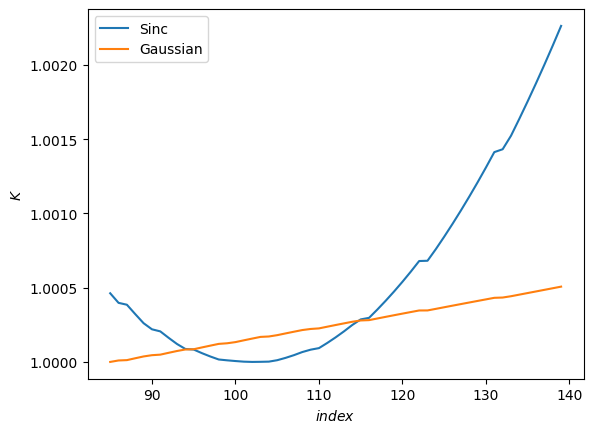

Sinc optimal value and index: 1.114288,102
Gaussian optimal value and index: 1.018439,85
Index which minimizes GVDp: 120
Ideal parameters (width,slab):(942.274130 nm,182.200000 nm)


In [19]:
fig, ax1 = plt.subplots()
ax1.plot(index_list, K / np.min(K), label="Sinc")
ax1.plot(index_list, Kg / np.min(Kg), label="Gaussian")
ax1.set_xlabel(r"$index$")
ax1.set_ylabel(r"$K$")
ax1.legend()
plt.show()
print("Sinc optimal value and index: %f,%i" % (K.min(), index_list[K.argmin()]))
print("Gaussian optimal value and index: %f,%i" % (Kg.min(), index_list[Kg.argmin()]))
print("Index which minimizes GVDp: %i" % index_gvdpmin)
print(
    "Ideal parameters (width,slab):(%f nm,%f nm)"
    % (p[index_list[K.argmin()], 0] / nm, p[index_list[K.argmin()], 1] / nm)
)

As we see, the configuration that minimizes GVDp is not the optimal case. In fact the optimal case is much closer to GVDs being maximized. We now include the low-gain JSA for the optimal case.

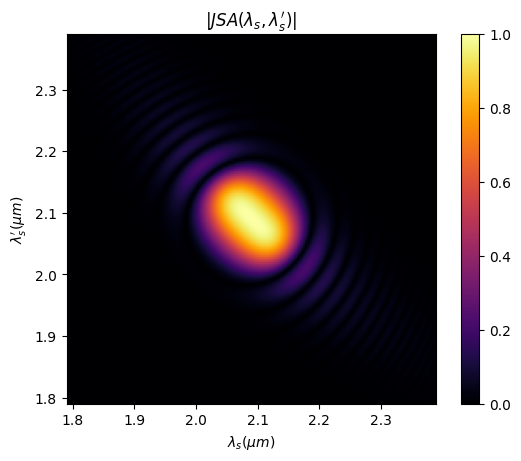

In [20]:
wg_test = waveguides.waveguide(
    w_top=p[index_list[K.argmin()], 0],
    h_thinfilm=hLN,
    h_etch=hLN - p[index_list[K.argmin()], 1],
    theta=angle,
    tf_material="LN_MgO_e",
    clad_material="Air",
    box_material="SiO2",
)
n1 = wg_test.neff(p_wl)[0]
n2 = wg_test.neff(s_wl)[0]
pp = p_wl / (n1 - n2)

# Finding dispersion for pump and signal as a function of wavelength range
# Since code requires 1D data, need to reshape things for pump
wlp = 1 / ((1 / wl + 1 / wl[:, np.newaxis])).flatten()
kp1 = 2 * np.pi * wg_test.neff(wlp) / (wlp)
kp = kp1.reshape(len(wl), len(wl))
ks = 2 * np.pi * wg_test.neff(wl) / (wl)

PMF_ideal = np.sinc(-L * (kp - ks - ks[:, np.newaxis] - 2 * np.pi / pp) / (2 * np.pi))

# Generating plot of low-gain JSA
fig, ax = plt.subplots()
im = ax.imshow(
    np.abs(PMF_ideal * pump),
    cmap="inferno",
    origin="lower",
    extent=[wl[0] / um, wl[-1] / um, wl[0] / um, wl[-1] / um],
)
ax.set_xlabel(r"$\lambda_s (\mu m)$")
ax.set_ylabel(r"$\lambda_s'(\mu m)$")
ax.set_title(r"$|JSA(\lambda_s,\lambda_s')|$")
plt.colorbar(im, orientation="vertical")
plt.show()

## Purity variations when away from ideal configuartion due to fabrication errors and finding the operation bandwidth from the JSA

With an optimal index at hand, we can now see how robust this configuration is. Experimentally, we will always be off from the optimal case when building these things. So we now consider the Schmidt numbers of configurations in the vicinity of the optimal case by varying the width and etch depths slightly.  There are many different ways we can check robustness, this is only one example.

In [21]:
# Variations in width/slab, we allow for both to possibly vary differently
dl = np.linspace(-10 * nm, 10 * nm, 11)
dl2 = np.linspace(-10 * nm, 10 * nm, 11)
K = np.zeros([len(dl), len(dl2)])

width = np.zeros(len(dl))
slab = np.zeros(len(dl2))

width = p[index_list[K.argmin()], 0] + dl
slab = p[index_list[K.argmin()], 1] + dl2


for i in tqdm(range(len(dl))):
    for j in range(len(dl2)):
        wg_test = waveguides.waveguide(
            w_top=width[i],
            h_thinfilm=hLN,
            h_etch=hLN - slab[j],
            theta=angle,
            tf_material="LN_MgO_e",
            clad_material="Air",
            box_material="SiO2",
        )
        # Obtaining poling period
        n1 = wg_test.neff(p_wl)[0]
        n2 = wg_test.neff(s_wl)[0]
        pp = p_wl / (n1 - n2)
        # Finding dispersion for pump and signal as a function of wavelength range
        # Since code requires 1D data, need to reshape things for pump
        wlp = 1 / ((1 / wl + 1 / wl[:, np.newaxis])).flatten()
        kp1 = 2 * np.pi * wg_test.neff(wlp) / (wlp)
        kp = kp1.reshape(len(wl), len(wl))
        ks = 2 * np.pi * wg_test.neff(wl) / (wl)
        # Different PMFs with Type-0 Phase-matching functions
        PMF_t = np.sinc(
            -L * (kp - ks - ks[:, np.newaxis] - 2 * np.pi / pp) / (2 * np.pi)
        )

        # Obtaining the Schmidt Numbers For configs
        L2, D, Vh = np.linalg.svd(0.000000001 * PMF_t * pump)
        D = np.diag(D)
        K[i, j] = (np.trace(np.sinh(D) ** 2)) ** 2 / np.trace(np.sinh(D) ** 4)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11/11 [06:48<00:00, 37.17s/it]


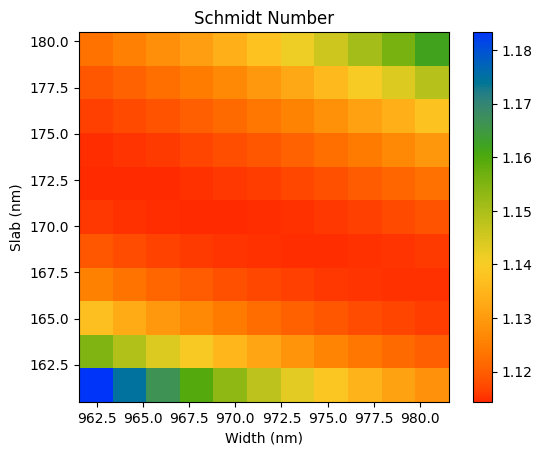

In [22]:
# Generating plot of Schmidt number for different configurations of width and slab.
fig, ax = plt.subplots()
im = ax.imshow(
    K.T,
    cmap=cc.cm["rainbow_r"],
    origin="lower",
    extent=[width[0] / nm, width[-1] / nm, slab[0] / nm, slab[-1] / nm],
    aspect=(width[-1] - width[0]) / (slab[-1] - slab[0]),
)
ax.set_xlabel("Width (nm)")
ax.set_ylabel("Slab (nm)")
ax.set_title("Schmidt Number")
plt.colorbar(im, orientation="vertical")
plt.show()

Here we try to obtain the operational bandwidth of the squeezed modes from the JSA. We take a cut along the diagonal and then obtain the width of the central blob. This is mostly to obtain a ball-park range for the bandwidth. Full high-gain analysis allows up to obtain the actual temporal mode sctructure of the generated signal modes, which then allows us to obtain the bandwidth of the mode.

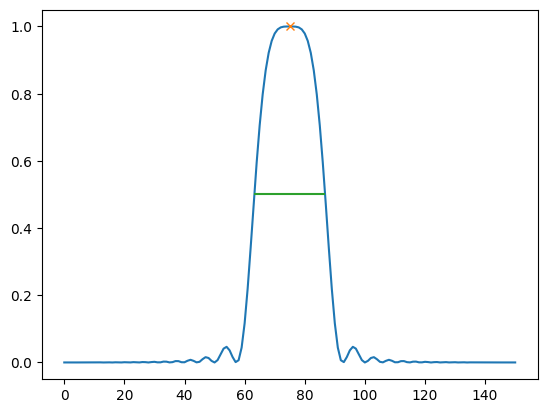

Operation bandwidth is : 94.093835 nm or 6.457870 THz


In [25]:
# Obtaining the JSA diagonal
diag = np.diag(np.flipud(np.abs(PMF_ideal * pump))) ** 2

# Finding the width at half-max
peaks, _ = find_peaks(diag, height=0.5, width=4)
result_half = peak_widths(diag, peaks, rel_height=0.5)
results_half = peak_widths(diag, peaks, rel_height=0.5)
plt.plot(diag)
plt.plot(peaks, diag[peaks], "x")
plt.hlines(*results_half[1:], color="C2")
plt.show()


print(
    "Operation bandwidth is : %f nm or %f THz"
    % (
        results_half[0][0] * (wl[1] - wl[0]) / (nm),
        c * results_half[0][0] * (wl[1] - wl[0]) / (s_wl) ** 2 / THz,
    )
)